# H DFT - Implementation

|                     |     |
| ------------------- | --- |
| **Status**          | 2026-11-11. Implemented in the engine and in the explorer; **off by default** (`thermo_mode` `'wb97mv'`), so every stored fit is unchanged |
| **Source**          | Y. Alcaraz Galván; DFT enthalpy and Gibbs energy (ωB97M-V/def2-TZVPD, RRHO, 298.15 K) from the snapshot |
| **Scope**           | Point 1 of `DFT_new_variables_rev02`: the gas-phase $G$ follows the temperature through the stored enthalpy $H$. How it is built, how to switch it on, and what it does to the stored fits (not refitted) |
| **Builds on**       | `DFT_new_variables_rev02` §1 (the proposal and its K factors), `fit_thermo_rev01` (the thermo fit and the kinetic fit of the 05/11/2026 tube) |

**In one line.** Until now the model used the DFT $G$ at 25 °C at every temperature. The snapshot also stores $H$, so the entropy is known, $S = (H - G)/298.15\ \text{K}$, and $G(T) = H - T\,S$. Nothing new is fitted.

| § | Question | Answer |
|---|---|---|
| 1 | Where does the change sit in the engine? | One function, `kinetics/thermo/gas.py` `_stored_gibbs`; a new `thermo_mode` `'wb97mv_T'` selects it |
| 2 | What does it do to each molecule? | $G$ moves by $-(T - 298.15)\,S$: about −0.15 eV per molecule at 80 °C, but mostly the same for all |
| 3 | What does it do to each reaction? | Only $\Delta S_\text{rxn}$ counts. At 80 °C $K$ of R1 ×4.6, R4 ×0.37; under 20 % at 30 °C |
| 4 | How is it switched on? | `"thermo_mode": "wb97mv_T"` in a run's `fit_config.json`; each fit records its mode and is refused under another |
| 5 | What happens to the stored fits? | Same parameters, other mode: χ² moves a little (room-temperature tubes are at 22–23 °C, not 25 °C) |

### Dependences

In [1]:
%load_ext autoreload
%autoreload 2

import json
import sys
from pathlib import Path

# The repository holds the code, the results and the data: run from notebooks/ or from the repository root
REPO = Path.cwd() if (Path.cwd() / 'kinetics').is_dir() else Path.cwd().parent
if str(REPO) in sys.path:
    sys.path.remove(str(REPO))
sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import kinetics
from kinetics.constants import EV_TO_KJ_MOL, R_SI, T_STD_K, ZERO_CELSIUS_K
from kinetics.data import format_equation, get_active_network, load_lab_observables
from kinetics.data.species import resolve_species_database
from kinetics.fitting import get_structure, load_fit_result
from kinetics.fitting.config import apply_fit_config, check_fit_setup
from kinetics.fitting.reporting import evaluate_fit, simulate_fit_trajectories, tabulate_fit_shares
from kinetics.fitting.residuals import REPORT_SOLVER, build_sample_set, calculate_residuals
from kinetics.fitting.thermo_fit import ThermoProblem, build_equilibrium_samples, load_thermo_setup
from kinetics.thermo import calculate_gas_thermo, calculate_network_thermo, get_active_thermo_mode, set_active_thermo_mode
from demo import style

assert Path(kinetics.__file__).parents[1] == REPO, f'kinetics was imported from {kinetics.__file__}, not from {REPO}'
style.apply_style()
pd.set_option('display.max_colwidth', None)

RESULTS = REPO / 'notebooks' / 'results'
MODES = {'wb97mv': 'G fixed at 25 °C', 'wb97mv_T': 'G follows T'}
config = apply_fit_config(RESULTS / 'thermo2_2pctH2O')          # EC/DEC 1:1 (2026-10-08 snapshot), network R1–R9 + N10–N15
print(f"Code: {REPO} · medium {config['medium'].label()} · network {config['network']} · active thermo mode {get_active_thermo_mode()}")

Code: /home/yeray/projects/atom-to-reactor · medium EC:DEC 0.50:0.50 by volume (x_EC 0.645, x_DEC 0.355), linear mixing, MD solvation of the 2026-10-08 snapshot · network R1-R9+N10-N15 · active thermo mode wb97mv


## 1. Where the change sits

The free energy of a molecule in solution is built in three layers, and each reaction energy from those. The change is in the first layer only; everything above it reads $G$ from there, so it follows without being touched.

```
   gas.py        G_gas,i(T)          ← here: 'wb97mv' G stored at 25 °C  |  'wb97mv_T' G = H − T·S
     │
   solution.py   G_sol,i = G_gas,i + ΔE_solv,i (MD, at its own temperature)
     │
   reaction.py   ΔG_rxn = Σ ν·G_sol,i ,  K_eq = exp(−ΔG_rxn / RT)
     │
   rates.py      ΔG‡ (Marcus, g per family) ,  k_f (Eyring) ,  k_r = k_f / K_eq
     │
   reactor / thermo fit / kinetic fit / explorer Predict
```

**The formula.** The snapshot stores, per molecule, the DFT enthalpy $H$ and Gibbs energy $G$ at $T_0 = 298.15$ K. Since $G = H - T_0 S$,

$$S = \frac{H - G(T_0)}{T_0}, \qquad G(T) = H - T\,S = G(T_0) - (T - T_0)\,S$$

$H$ and $S$ are kept at their 25 °C values (no heat capacity). For a reaction, $\Delta G_\text{rxn}(T) = \Delta G_\text{rxn}(T_0) - (T - T_0)\,\Delta S_\text{rxn}$, so

$$\frac{K_\text{eq}(T)\ \text{with}\ G(T)}{K_\text{eq}(T)\ \text{with}\ G\ \text{fixed}} = \exp\!\left(\frac{(T - T_0)\,\Delta S_\text{rxn}}{RT}\right)$$

**What was changed in the code.**

| File | Change |
|---|---|
| `kinetics/thermo/gas.py` | `THERMO_MODES` gains `'wb97mv_T'`; `_stored_gibbs(data, T_K)` returns $H - T S$ when given a temperature. An **active mode** (`set_active_thermo_mode`, `get_active_thermo_mode`) is used wherever no mode is passed, like the active medium and network |
| `kinetics/thermo/solution.py`, `reaction.py`, `microkinetics/rates.py`, `models.py` | `thermo_mode` defaults to `None` = the active mode. No standard-state shift in either stored mode (it cancels: every reaction keeps the number of molecules) |
| `kinetics/fitting/config.py` | key `thermo_mode` of `fit_config.json` (default `'wb97mv'`), made active by `apply_fit_config`; `check_fit_setup` refuses a fit stored under another mode |
| `scripts/run_fit.py`, `scripts/run_thermo_fit.py` | each stored fit records `thermo_mode`; the log prints it |
| `private/explorer` | Predict: switch *Gas-phase G: fixed at 25 °C / follows T*. Reactions: ΔS and the K factor at a chosen temperature |

The MD solvation energy $\Delta E_\text{solv}$ is **not** moved with $T$: only the gas-phase part follows the temperature.

## 2. Each molecule

$H$, $G$ at 25 °C, the entropy $S$ from them, and $G$ at 80 °C under each mode, all read through the engine (`calculate_gas_thermo`). $G$ drops by about 0.15 eV per molecule at 80 °C, but every molecule drops by a similar amount; only the differences between products and reactants reach a reaction (§3).

In [2]:
# §2: per molecule, through the engine in both modes. G and H in eV, S in J/(mol·K)
T_HOT = 80.0 + ZERO_CELSIUS_K
db = resolve_species_database()
species = sorted({sp for r in get_active_network().values() for side in ('reactants', 'products') for sp in r[side]})
rows = []
for sp in species:
    fixed = calculate_gas_thermo(sp, T_HOT, thermo_mode='wb97mv')
    moving = calculate_gas_thermo(sp, T_HOT, thermo_mode='wb97mv_T')
    rows.append({'species': sp, 'H (eV)': db[sp]['H_gas_eV'], 'G 25 °C (eV)': db[sp]['G_gas_eV'],
                 'S (J/mol·K)': moving['S_gas_J_mol_K'],
                 'G 80 °C, fixed (eV)': fixed['G_gas_eV'], 'G 80 °C, follows T (eV)': moving['G_gas_eV'],
                 'moved at 80 °C (eV)': moving['G_gas_eV'] - fixed['G_gas_eV']})
per_species = pd.DataFrame(rows).set_index('species')
assert np.allclose(per_species['G 80 °C, fixed (eV)'], per_species['G 25 °C (eV)'])     # 'wb97mv': G does not move
display(per_species.style.format({c: '{:.3f}' for c in per_species.columns if c != 'S (J/mol·K)'} | {'S (J/mol·K)': '{:.1f}'})
        .set_caption('Gas-phase H, G and S of each molecule (DFT, RRHO); G at 80 °C under each mode'))

,H (eV),G 25 °C (eV),S (J/mol·K),"G 80 °C, fixed (eV)","G 80 °C, follows T (eV)",moved at 80 °C (eV)
species,,,,,,
BMSPA,-39765.580,-39767.419,595.2,-39767.419,-39767.758,-0.339
CO2,-5132.313,-5132.972,213.4,-5132.972,-5133.094,-0.122
EC,-9316.113,-9317.044,301.1,-9317.044,-9317.215,-0.172
H2O,-2079.181,-2079.764,188.6,-2079.764,-2079.872,-0.108
H3PO4,-17529.515,-17530.505,320.3,-17530.505,-17530.688,-0.183
HMDSO,-24314.906,-24316.469,505.9,-24316.469,-24316.757,-0.288
MMSPA,-28647.527,-28648.983,471.2,-28648.983,-28649.252,-0.269
TMSOEG,-17381.046,-17382.445,452.8,-17382.445,-17382.703,-0.258
TMSOH,-13196.895,-13198.051,373.9,-13198.051,-13198.264,-0.213


## 3. Each reaction

Now through the whole chain (`calculate_network_thermo`): $K_\text{eq}$ under each mode, and their ratio. At 25 °C the two modes are the same number; they part as the tube is heated or cooled. This is the table of `DFT_new_variables_rev02` §1, now produced by the engine.

In [3]:
# §3: K_eq with G following T over K_eq with G fixed, from the engine (both modes), at the temperatures of the lab tubes
network = get_active_network()                                     # R1–R9 + N10–N15


def k_ratio(T_C):
    T_K = T_C + ZERO_CELSIUS_K
    fixed = calculate_network_thermo(T_K, network=network, thermo_mode='wb97mv')
    moving = calculate_network_thermo(T_K, network=network, thermo_mode='wb97mv_T')
    return moving['K_eq'] / fixed['K_eq'], fixed


dS = pd.Series({r: sum(sign * nu * (db[sp]['H_gas_eV'] - db[sp]['G_gas_eV']) * EV_TO_KJ_MOL * 1000.0 / T_STD_K
                       for side, sign in (('products', 1), ('reactants', -1)) for sp, nu in network[r][side].items())
                for r in network})
TEMPS_C = (22.3, 30, 50, 80)
table = pd.DataFrame({'reaction': {r: format_equation({'id': r, **network[r]}) for r in network}, 'ΔS (J/mol·K)': dS,
                      **{f'K × at {t:g} °C': k_ratio(t)[0] for t in TEMPS_C}})
# check against the closed formula of §1: exp((T − T0)·ΔS / RT)
for t in TEMPS_C:
    T_K = t + ZERO_CELSIUS_K
    assert np.allclose(table[f'K × at {t:g} °C'], np.exp((T_K - T_STD_K) * dS / (R_SI * T_K)))
assert np.allclose(k_ratio(25.0)[0], 1.0)
display(table.style.format({'ΔS (J/mol·K)': '{:+.1f}', **{f'K × at {t:g} °C': '×{:.2f}' for t in TEMPS_C}})
        .set_caption('How much K_eq moves when G follows T (engine, both modes); 22.3 °C: the 05/11/2026 tube'))

,reaction,ΔS (J/mol·K),K × at 22.3 °C,K × at 30 °C,K × at 50 °C,K × at 80 °C
R1,TMSPA + H2O ⇌ BMSPA + TMSOH,+81.2,×0.91,×1.17,×2.13,×4.58
R2,BMSPA + H2O ⇌ MMSPA + TMSOH,+61.3,×0.93,×1.13,×1.77,×3.15
R3,MMSPA + H2O ⇌ H3PO4 + TMSOH,+34.3,×0.96,×1.07,×1.38,×1.90
R4,2 TMSOH ⇌ HMDSO + H2O,-53.4,×1.06,×0.90,×0.61,×0.37
R5,TMSPA + TMSOH ⇌ BMSPA + HMDSO,+27.9,×0.97,×1.06,×1.30,×1.69
R6,BMSPA + TMSOH ⇌ MMSPA + HMDSO,+8.0,×0.99,×1.02,×1.08,×1.16
R7,MMSPA + TMSOH ⇌ H3PO4 + HMDSO,-19.0,×1.02,×0.96,×0.84,×0.70
R8,EC + TMSOH ⇌ TMSOEG + CO2,-8.8,×1.01,×0.98,×0.92,×0.85
R9,EC + TMSOEG ⇌ TMSOdiEG + CO2,-23.5,×1.03,×0.95,×0.80,×0.64
N10,2 BMSPA ⇌ MMSPA + TMSPA,-19.9,×1.02,×0.96,×0.83,×0.69


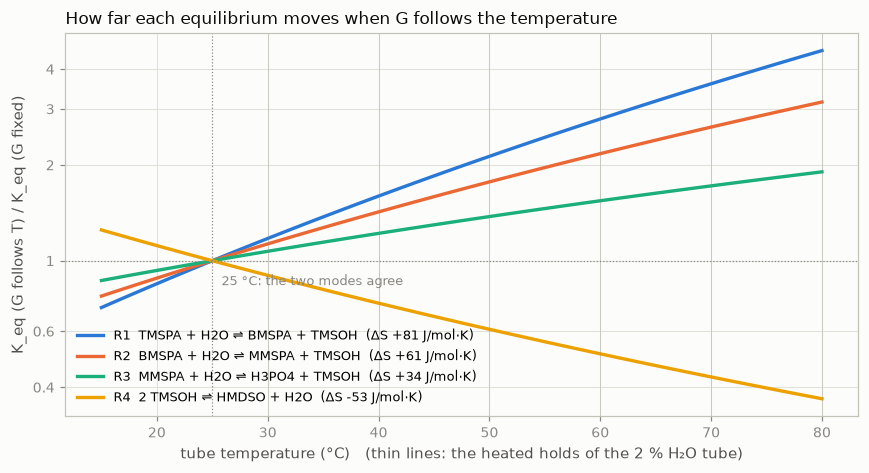

In [4]:
# §3, figure: the K factor of the four reactions the thermo fit uses (R1–R4), 15–80 °C
T_C = np.linspace(15, 80, 66)
ratios = pd.DataFrame([k_ratio(t)[0] for t in T_C], index=T_C)
fig, ax = plt.subplots(figsize=(8, 4.4))
for i, r in enumerate(['R1', 'R2', 'R3', 'R4']):
    ax.plot(T_C, ratios[r], color=style.SERIES[i], lw=2.2, label=f"{r}  {table.loc[r, 'reaction']}  (ΔS {dS[r]:+.0f} J/mol·K)")
ax.axhline(1, color=style.INK_MUTED, lw=0.8, ls=':')
ax.axvline(25, color=style.INK_MUTED, lw=0.8, ls=':')
ax.annotate('25 °C: the two modes agree', (25, 1), xytext=(6, -16), textcoords='offset points', fontsize=8.5, color=style.INK_MUTED)
for t in (30, 40, 50, 60, 70, 80):
    ax.axvline(t, color=style.INK_MUTED, lw=0.5, alpha=0.35)
ax.set_yscale('log')
ax.set_yticks([0.4, 0.6, 1, 2, 3, 4]); ax.set_yticklabels(['0.4', '0.6', '1', '2', '3', '4']); ax.minorticks_off()
ax.set_xlabel('tube temperature (°C)   (thin lines: the heated holds of the 2 % H₂O tube)')
ax.set_ylabel('K_eq (G follows T) / K_eq (G fixed)')
ax.set_title('How far each equilibrium moves when G follows the temperature', loc='left')
ax.legend(fontsize=8.5, loc='lower left')
plt.tight_layout(); plt.show()

**What it means.**
- Hydrolysis (R1–R3) makes floppier molecules ($\Delta S > 0$): it is favoured more when hot. At 80 °C, R1 ×4.6, R2 ×3.2, R3 ×1.9.
- Condensation R4 (2 TMSOH → HMDSO + H₂O) loses entropy: ×0.37 at 80 °C, so less HMDSO when hot.
- Below 25 °C it goes the other way. At 22.3 °C (the 05/11/2026 tube) R1 is ×0.91: small, but not zero.

## 4. How to switch it on

A run chooses its mode in `fit_config.json`, beside the medium and the network:

```json
{ "solvation": {...}, "network": "R1-R9+N10-N15", "thermo_mode": "wb97mv_T", ... }
```

`apply_fit_config` makes it the active mode, so everything after it (fits, notebooks, the explorer) uses it without passing it around. A run without the key keeps `'wb97mv'`, the behaviour of every fit so far. Each new fit stores the mode it was computed with, and `check_fit_setup` refuses to run a stored fit forward under another mode, as it already does for the medium and the network. In code, `set_active_thermo_mode('wb97mv_T')` switches it for a session and `set_active_thermo_mode()` goes back to the default.

In [5]:
# §4: the guard. A stored fit without the record counts as 'wb97mv'; under the other mode it is refused
fit_k1 = load_fit_result(str(RESULTS / 'kin_M1_2pct-261105_Esolv-thermo2' / 'steps' / 'M1__K1__10_min.json'))
apply_fit_config(RESULTS / 'kin_M1_2pct-261105_Esolv-thermo2')
print('recorded thermo_mode:', fit_k1.get('thermo_mode', "none (counts as 'wb97mv')"), '· active:', get_active_thermo_mode())
check_fit_setup(fit_k1)                                              # passes
set_active_thermo_mode('wb97mv_T')
try:
    check_fit_setup(fit_k1)
except ValueError as error:
    print('refused:', error)
finally:
    set_active_thermo_mode()                                         # back to the default

recorded thermo_mode: none (counts as 'wb97mv') · active: wb97mv
refused: this fit was computed with thermo_mode 'wb97mv', the active one is 'wb97mv_T': call apply_fit_config(<its results directory>) first


## 5. What it does to the stored fits

The fits so far were all made with $G$ fixed. Here each one is **scored again with the same parameters** under the other mode, not refitted: it says how much the switch moves the model where the data are, not what a new fit would find.

- **thermo2** (`thermo2_2pctH2O`, ξ = 1): the 2 % H₂O tube at equilibrium, spectra at 22.6 °C.
- **K1** (`kin_M1_2pct-261105_Esolv-thermo2`): M1 on the 05/11/2026 tube alone, 22.3 °C.
- **S5** (`fit8_M1-steps_S1-tube`, 1 h reading): M1 tube by tube, last step; the 2 % H₂O tube has the six heated holds (30–80 °C, 8 h each).

In [6]:
# §5: χ² of each stored fit, same parameters, under each mode. The 'wb97mv' column must give back the stored χ²
def thermo_scores(run, xi=1):
    config = apply_fit_config(RESULTS / run)
    setup = load_thermo_setup(config)
    fit = load_fit_result(str(RESULTS / run / 'steps' / f'thermo__S1__xi{xi:g}.json'))
    observables = load_lab_observables(config['observables'])
    out = []
    for mode in MODES:
        set_active_thermo_mode(mode)                                  # before the problem: it computes G_sol,i once
        samples = build_equilibrium_samples(pd.read_csv(RESULTS / run / 'spectra_shares.csv'),
                                            pd.read_csv(RESULTS / run / 'equilibrium_points.csv'), observables,
                                            setup['nuclei'], error_model=setup['error_model'])
        samples = [s for s in samples if s['name'] in fit['step_fit']]
        problem = ThermoProblem(samples, free_species=setup['free_species'], xi=xi, reactions=setup['reactions'],
                                sigma_solv=setup['sigma_solv']).replace(fixed=fit['theta'])
        z = problem.residuals(np.zeros(0))
        out += [{'fit': f'thermo2 (ξ = {xi:g})', 'tube': s['name'], 'T (°C)': s['T_K'] - ZERO_CELSIUS_K, 'mode': mode,
                 'χ²': float(z @ z), 'points': z.size, 'stored χ²': fit['chi2']} for s in samples]
    set_active_thermo_mode(config['thermo_mode'])
    return out


def kinetic_scores(run, file, label, tubes=None):
    config = apply_fit_config(RESULTS / run)
    fit = load_fit_result(str(RESULTS / run / 'steps' / file))
    observables = load_lab_observables(config['observables'])
    out = []
    for mode in MODES:
        set_active_thermo_mode(mode)
        built = get_structure(fit['structure']).build(fit['theta'])
        for sample in build_sample_set(observables, fit['scenario']):
            if tubes and sample['name'] not in tubes:
                continue
            z = calculate_residuals(built['model'], [sample], added_M=built['added_M'], solver=REPORT_SOLVER)
            hot = [T - ZERO_CELSIUS_K for _, T, _ in sample.get('heated', ())]
            out.append({'fit': label, 'tube': sample['name'], 'T (°C)': sample['T_rt_K'] - ZERO_CELSIUS_K,
                        'heated': (f'{min(hot):g}–{max(hot):g} °C' if min(hot) != max(hot) else f'{min(hot):g} °C') if hot else '', 'mode': mode,
                        'χ²': float(z @ z), 'points': z.size, 'stored χ²': fit['chi2']})
    set_active_thermo_mode(config['thermo_mode'])
    return out


S5_TUBES = None                                                     # every tube of the step's sample set
scores = pd.DataFrame(thermo_scores('thermo2_2pctH2O')
                      + kinetic_scores('kin_M1_2pct-261105_Esolv-thermo2', 'M1__K1__10_min.json', 'K1 (05/11/2026 tube)')
                      + kinetic_scores('fit8_M1-steps_S1-tube', 'M1__S5__1_h.json', 'S5 (M1 steps, 1 h)', S5_TUBES))
wide = scores.pivot_table(index=['fit', 'tube'], columns='mode', values='χ²', sort=False)
info = scores.drop_duplicates(['fit', 'tube']).set_index(['fit', 'tube'])
wide = pd.concat([info[['T (°C)', 'heated', 'points']].fillna(''), wide[list(MODES)].rename(columns=MODES)], axis=1)
wide['change'] = wide[MODES['wb97mv_T']] - wide[MODES['wb97mv']]
# the fixed mode gives back what each run stored (K1 and thermo2: the one tube; S5: the 2 % H2O tube it fits)
assert np.isclose(wide.loc[('thermo2 (ξ = 1)', '2 % H2O'), MODES['wb97mv']], info.loc[('thermo2 (ξ = 1)', '2 % H2O'), 'stored χ²'])
assert np.isclose(wide.loc[('K1 (05/11/2026 tube)', '2 % H2O, 05/11/2026'), MODES['wb97mv']], info.loc[('K1 (05/11/2026 tube)', '2 % H2O, 05/11/2026'), 'stored χ²'])
display(wide.style.format({'T (°C)': '{:.1f}', MODES['wb97mv']: '{:.1f}', MODES['wb97mv_T']: '{:.1f}', 'change': '{:+.1f}'})
        .set_caption('χ² of each stored fit per tube, same parameters, G fixed vs G following T (not refitted)'))

**What it means.**
- The **room-temperature fits move a little**, because the tubes sat at 22–23 °C, not at 25 °C: thermo2 and K1 each gain about 1 in χ². `DFT_new_variables_rev02` said thermo2 "does not change"; that is true only for a tube at exactly 25 °C.
- The **heated 2 % H₂O tube** (S5) moves by about +20 in a χ² of about 9 400, and the 0.5 % tube by about −20 in 2 200: the switch does not explain why these tubes fit badly (§5.1). S5 fits only the 2 % H₂O tube; the other rows are its parameters scored on the remaining tubes.
- Real effects need a **refit** with `"thermo_mode": "wb97mv_T"` (the barriers $g$ and the thermo shifts were fitted with $G$ fixed). Not launched here.

### 5.1 The heated tube, drawn

The 2 % H₂O tube under S5: the model under each mode (solid: $G$ fixed; dashed: $G$ follows T), the measured ³¹P (points), and the temperature history. Same parameters.

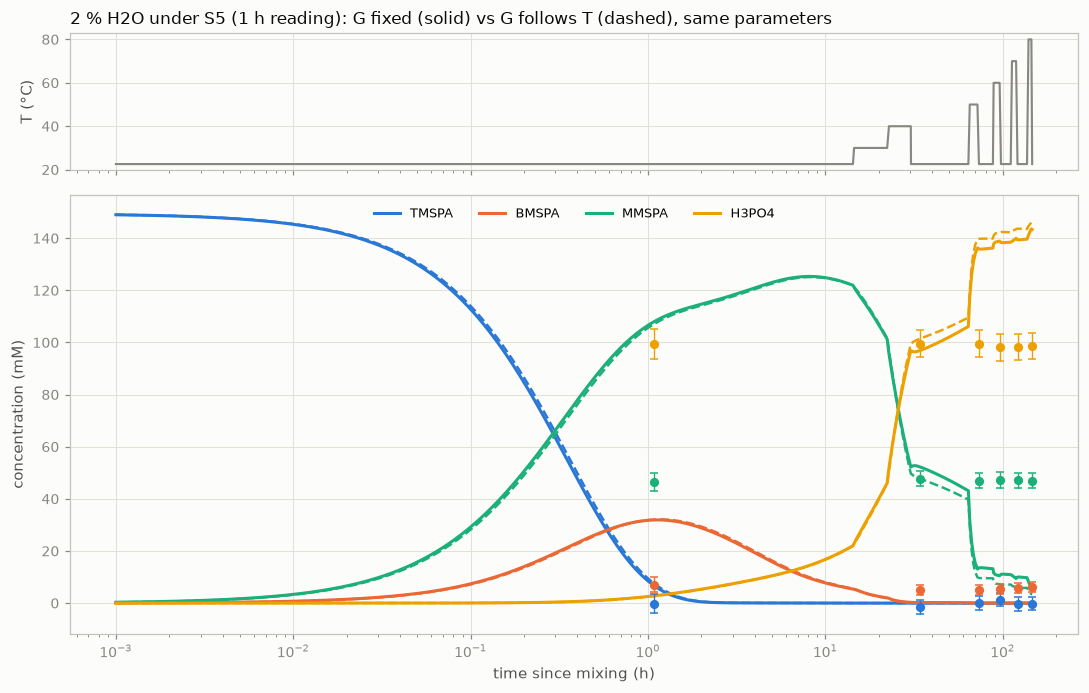

In [7]:
# §5.1: C(t) of the phosphate species of the 2 % H2O tube under S5 (1 h), both modes; points: ³¹P share × total P
S5_RUN, S5_TUBE = RESULTS / 'fit8_M1-steps_S1-tube', '2 % H2O'
config_s5 = apply_fit_config(S5_RUN)
fit_s5 = load_fit_result(str(S5_RUN / 'steps' / 'M1__S5__1_h.json'))
obs_s5 = load_lab_observables(config_s5['observables'])
curves, shares = {}, None
try:
    for mode in MODES:
        set_active_thermo_mode(mode)
        evaluation = evaluate_fit({**fit_s5, 'thermo_mode': mode}, obs_s5)       # same θ, scored under this mode
        rows = simulate_fit_trajectories(evaluation, t_first_h=1e-3, n_points=500)
        curves[mode] = rows[rows['sample'] == S5_TUBE]
        if shares is None:
            shares = tabulate_fit_shares(evaluation).query('sample == @S5_TUBE and nucleus == "31P"')
finally:
    set_active_thermo_mode(config_s5['thermo_mode'])

fig, (ax_T, ax) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True, gridspec_kw={'height_ratios': [1, 3.2]})
base = curves['wb97mv']
ax_T.plot(base['t_h'], base['T_C'], color=style.INK_MUTED, lw=1.4)
ax_T.set_ylabel('T (°C)')
ax_T.set_title(f'{S5_TUBE} under S5 (1 h reading): G fixed (solid) vs G follows T (dashed), same parameters', loc='left')
for k, sp in enumerate(['TMSPA', 'BMSPA', 'MMSPA', 'H3PO4']):
    colour = style.SERIES[k]
    ax.plot(base['t_h'], 1000 * base[sp], color=colour, lw=2, label=sp)
    ax.plot(curves['wb97mv_T']['t_h'], 1000 * curves['wb97mv_T'][sp], color=colour, lw=1.6, ls='--')
    seen = shares[shares['window'] == sp]
    ax.errorbar(seen['t_h'], 1000 * seen['measured'] * seen['total_M'], yerr=1000 * seen['sigma'] * seen['total_M'],
                fmt='o', color=colour, markersize=5, capsize=2.5, elinewidth=0.9, zorder=4)
ax.set_xscale('log')
ax.set_xlabel('time since mixing (h)')
ax.set_ylabel('concentration (mM)')
ax.legend(ncols=4, fontsize=8.5, loc='upper center')
plt.tight_layout(); plt.show()

**What the figure shows.** Up to the 40 °C hold the two modes are the same curve. From the 50 °C hold on, with $G$ following T more MMSPA turns into H₃PO₄ (R3 is ×1.4–1.9 at 50–80 °C), so the model moves a little further from the measured MMSPA (≈ 47 mM) and H₃PO₄ (≈ 98 mM). Under both modes the model is already far from those points (MMSPA about 10 mM against 47), so the misfit of this tube comes from elsewhere, not from $G$ being fixed.

## 6. Limits

- **Only the gas-phase part follows $T$.** The MD solvation energy is computed at one temperature and stays there. If solvation entropy is large, this is the bigger missing piece.
- **$S$ is RRHO from DFT.** Every reaction here keeps two molecules on each side, so the large translational and rotational terms largely cancel in $\Delta S_\text{rxn}$; low-frequency modes are the remaining error (`'qRRHO'` would treat them, but the snapshot has no frequencies).
- **$H$ and $S$ do not change with $T$** (no heat capacity). Over 25–80 °C this is a small second-order term.
- **Default unchanged.** All stored fits and notebooks keep `'wb97mv'`. A fit with `'wb97mv_T'` needs a new run directory with the key in its `fit_config.json`.

In [8]:
apply_fit_config(RESULTS / 'thermo2_2pctH2O')                 # leave the session in the default setup
print('active thermo mode:', get_active_thermo_mode())

active thermo mode: wb97mv
